 Write a program to enhance the contrast of the input grayscale image
using histogram equalization. Display the original image and equalized
image.

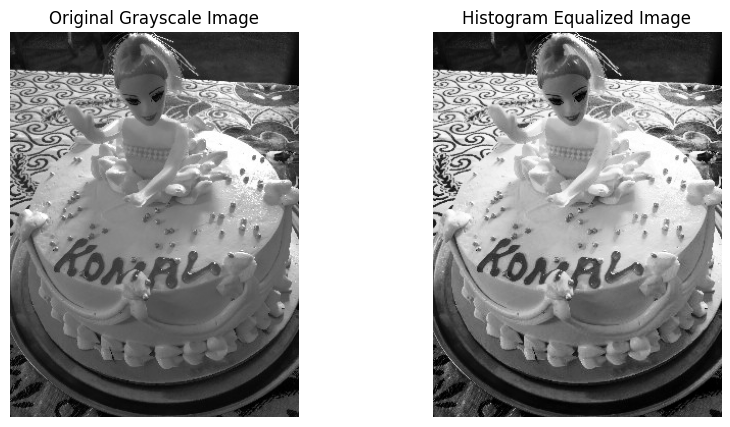

In [2]:

import cv2
import matplotlib.pyplot as plt

# Read the input image in grayscale
img = cv2.imread("/content/1000023910.jpg", cv2.IMREAD_GRAYSCALE)

# Check whether image is loaded
if img is None:
    print("Error: Image not found!")
else:
    # Apply histogram equalization
    equalized_img = cv2.equalizeHist(img)

    # Display original and equalized images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(equalized_img, cmap='gray')
    plt.title("Histogram Equalized Image")
    plt.axis("off")

    plt.show()


Write a program to perform histogram matching of the input image with
that of reference image using histogram equalization

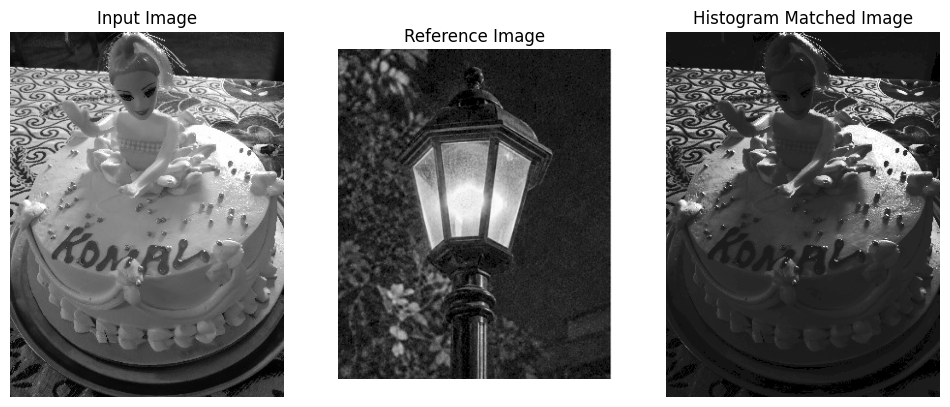

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images in grayscale
input_img = cv2.imread("/content/1000023910.jpg", cv2.IMREAD_GRAYSCALE)
reference_img = cv2.imread("/content/denoising.png", cv2.IMREAD_GRAYSCALE)

# Check images
if input_img is None or reference_img is None:
    print("Error: Image not found!")
else:
    # Calculate histograms
    hist_input = cv2.calcHist([input_img], [0], None, [256], [0, 256])
    hist_reference = cv2.calcHist([reference_img], [0], None, [256], [0, 256])

    # Calculate cumulative distribution functions (CDF)
    cdf_input = hist_input.cumsum()
    cdf_reference = hist_reference.cumsum()

    # Normalize CDFs
    cdf_input = cdf_input / cdf_input[-1]
    cdf_reference = cdf_reference / cdf_reference[-1]

    # Create mapping
    mapping = np.zeros(256, dtype=np.uint8)

    for i in range(256):
        mapping[i] = np.argmin(np.abs(cdf_reference - cdf_input[i]))

    # Apply histogram matching
    matched_img = cv2.LUT(input_img, mapping)

    # Display images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(input_img, cmap='gray')
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(reference_img, cmap='gray')
    plt.title("Reference Image")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(matched_img, cmap='gray')
    plt.title("Histogram Matched Image")
    plt.axis("off")

    plt.show()
